# Deep Learning: More Recurrent Neural Networks

In [1]:
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
import os, re, zipfile, urllib.request
from collections import Counter
from tqdm import tqdm
import matplotlib.pyplot as plt

In [2]:
# DEVICE CONFIGURATION
if torch.backends.mps.is_available():          # Apple Silicon
    device = torch.device("mps")
elif torch.cuda.is_available():                # CUDA GPU
    device = torch.device("cuda")
else:
    device = torch.device("cpu")               # Fallback

print("Using device:", device)

Using device: cpu


## Helper Functions

- Downloads dataset
- Reads files
- Mimics old utilties that have been deprecated

In [3]:
DATA_DIR = "sst2_data"
ZIP_PATH = os.path.join(DATA_DIR, "SST-2.zip")
SST_DIR  = os.path.join(DATA_DIR, "SST-2")

os.makedirs(DATA_DIR, exist_ok=True)

if not os.path.exists(os.path.join(SST_DIR, "train.tsv")):
    if not os.path.exists(ZIP_PATH):
        print("Downloading SST-2 ...")
        SST_URL = "https://dl.fbaipublicfiles.com/glue/data/SST-2.zip"
        urllib.request.urlretrieve(SST_URL, ZIP_PATH)
    print("Extracting ...")
    with zipfile.ZipFile(ZIP_PATH) as zf:
        zf.extractall(DATA_DIR)

# Read TSV files
def read_sst(path):
    """Read an SST-2 TSV that has a `sentence\\tlabel` header."""
    rows = []
    with open(path, encoding="utf-8") as f:
        header = f.readline().strip().split("\t")
        text_col  = header.index("sentence") if "sentence" in header else 1
        label_col = header.index("label")    if "label"    in header else None
        for line in f:
            parts = line.rstrip("\n").split("\t")
            if len(parts) <= max(text_col, label_col or 0):
                continue
            text  = parts[text_col]
            label = int(float(parts[label_col])) if label_col is not None else 0
            rows.append((text, label))
    return rows

Extracting ...


In [4]:
# Tokenizer (approximates deprecated torchtext 'basic_english') ----------
_PUNCT = re.compile(r"([.,!?;:'\"()\[\]{}<>@#$%^&*~`|=+\\/-])")

def tokenize(text):
    text = text.lower()
    text = _PUNCT.sub(r" \1 ", text)   # split punctuation off words
    return text.split()

In [5]:
class Vocab:
    def __init__(self, examples, max_size=10000):
        counter = Counter()
        for text, _ in examples:
            counter.update(tokenize(text))
        self.itos = ["<pad>", "<unk>"]
        for word, _ in counter.most_common(max_size):
            if word not in self.stoi if hasattr(self, "stoi") else True:
                self.itos.append(word)
        self.stoi = {w: i for i, w in enumerate(self.itos)}
    def __len__(self):
        return len(self.itos)

## Download and Read Dataset

Now we're ready to use this help functions!

In [6]:
train_data = read_sst(os.path.join(SST_DIR, "train.tsv"))
test_data  = read_sst(os.path.join(SST_DIR, "dev.tsv"))   # dev.tsv HAS labels

# Display size of datasets
print(f"train: {len(train_data)} examples | test: {len(test_data)} examples")

train: 67349 examples | test: 872 examples


In [7]:
MAX_VOCAB_SIZE = 10000
vocab  = Vocab(train_data, max_size=MAX_VOCAB_SIZE)
pad_idx = vocab.stoi["<pad>"]

print(f"vocab size: {len(vocab)} | pad_idx: {pad_idx}")

vocab size: 10002 | pad_idx: 0


The `.splits` method is splitting up our dataset so that our train and test sets both have representative samples. 

The `fine_grained` parameter determines how many categories our data is broken into.
- if `True`: labels can be {'positive': 0, 'negative': 1, 'neutral': 2, 'very positive': 3, 'very negative': 4}
- if `False`: labels can be {'positive': 0, 'negative': 1, 'neutral': 2}

In [8]:
# Build vocabulary
MAX_VOCAB_SIZE = 10000
vocab = Vocab(train_data, max_size=MAX_VOCAB_SIZE)
pad_idx = vocab.stoi["<pad>"]

### Q: What variable type is `vocab`?
Hint: `.stoi` stand for "string to int"!

### A: 
It's an instance of the Vocab class

In [9]:
def decode_dataset(examples):
    texts = [tokenize(text) for text, _ in examples]
    labels = [label for _, label in examples]
    return texts, labels

train_texts, train_labels = decode_dataset(train_data)
test_texts, test_labels   = decode_dataset(test_data)

### Sanity Check 🧠 
Let's check that the decoded dataset makes sense!

In [10]:
# SST-2 labels are binary: 0 = negative, 1 = positive
label_map = {0: "negative", 1: "positive"}

# Change i and see what happens!
i = 0

print(" ".join(tokenize(test_data[i][0])))
print(label_map[int(test_labels[i])])

it ' s a charming and often affecting journey .
positive


----

Now let's define a `BucketIterator`:

In [11]:
BATCH_SIZE = 32
class SSTDataset(Dataset):
    def __init__(self, examples, vocab):
        self.examples = examples
        self.vocab = vocab

    def __len__(self):
        return len(self.examples)

    def __getitem__(self, idx):
        text, label = self.examples[idx]
        ids = [self.vocab.stoi.get(t, self.vocab.stoi["<unk>"]) for t in tokenize(text)]
        return torch.tensor(ids, dtype=torch.long), torch.tensor(label, dtype=torch.float)

def collate_fn(batch):
    # Sort by length descending (the modern equivalent of BucketIterator's sort_key),
    # and pad to [seq_len, batch] because SimpleLSTM uses batch_first=False.
    batch = sorted(batch, key=lambda x: len(x[0]), reverse=True)
    texts, labels = zip(*batch)
    lengths = torch.tensor([len(t) for t in texts], dtype=torch.long)
    padded = nn.utils.rnn.pad_sequence(texts, batch_first=False, padding_value=pad_idx)
    return padded, lengths, torch.stack(labels)

train_iterator = DataLoader(
    SSTDataset(train_data, vocab),
    batch_size=BATCH_SIZE, shuffle=True, collate_fn=collate_fn,
)
test_iterator = DataLoader(
    SSTDataset(test_data, vocab),
    batch_size=BATCH_SIZE, shuffle=False, collate_fn=collate_fn,
)

Below is a custom classifier:

In [12]:
# Custom LSTM Classifier
class SimpleLSTM(nn.Module):
    def __init__(self, vocab_size, embedding_dim, hidden_dim, output_dim, pad_idx):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, embedding_dim, padding_idx=pad_idx)
        self.lstm = nn.LSTM(embedding_dim, hidden_dim, batch_first=False)
        self.fc = nn.Linear(hidden_dim, output_dim)

    def forward(self, text, text_lengths):
        # text: [batch_size, seq_len] if batch_first=True
        embedded = self.embedding(text)  # [batch_size, seq_len, emb_dim]

        # Pack padded sequence
        packed_embedded = nn.utils.rnn.pack_padded_sequence(embedded, text_lengths.cpu(), batch_first=False, enforce_sorted=False)
        packed_output, (hidden, cell) = self.lstm(packed_embedded)

        # hidden: [1, batch_size, hidden_dim]  -> take the last hidden state
        return self.fc(hidden.squeeze(0))  # [batch_size, output_dim]

Here's a helper function so we can vary parameters later:

In [13]:
# TRAINING LOOP FUNCTION
def run_training_loop(num_epochs, random_state):
    # set random seed
    torch.manual_seed(random_state)

    EMBEDDING_DIM = 100
    HIDDEN_DIM = 256
    OUTPUT_DIM = 1

    # Send model to device
    model = SimpleLSTM(len(vocab), EMBEDDING_DIM, HIDDEN_DIM, OUTPUT_DIM, pad_idx).to(device)
    criterion = nn.BCEWithLogitsLoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=0.001)

    # init output vars
    train_losses = []
    train_accs = []

    # train for num_epochs
    for epoch in range(num_epochs):
        model.train()
        epoch_loss = 0
        epoch_acc = 0

        # Wrap the iterator with tqdm
        for text, text_lengths, labels in tqdm(train_iterator, desc=f"Epoch {epoch+1}/{num_epochs}"):
            text, text_lengths, labels = text.to(device), text_lengths.to(device), labels.to(device)

            text, text_lengths, labels = text.to(device), text_lengths.to(device), labels.to(device)

            optimizer.zero_grad()
            predictions = model(text, text_lengths).squeeze(1)

            # Loss
            loss = criterion(predictions, labels.float())
            loss.backward()
            optimizer.step()

            # Optional: compute accuracy
            preds = torch.round(torch.sigmoid(predictions))
            acc = (preds == labels).float().mean()
            epoch_loss += loss.item()
            epoch_acc += acc.item()
        
        avg_loss = epoch_loss/ len(train_iterator)
        avg_acc = epoch_acc/ len(train_iterator)
        train_losses.append(avg_loss)
        train_accs.append(avg_acc)
        print(f"Loss = {avg_loss:.4f}, Accuracy = {avg_acc:.4f}\n")
    return train_losses, train_accs, model

And another helper function plot the `train_losses` and `train_accs`:

In [14]:
def plot_training_performance(train_losses, train_accs, num_epochs, random_state):
    fig = plt.figure(figsize=(8,4), tight_layout=True)
    fig.suptitle(f"Model Training for State {random_state} over {num_epochs} Epochs")

    plt.subplot(1,2,1)
    plt.plot(train_losses, "-o", label="Train Loss")
    plt.xlabel("Epoch")
    plt.ylabel("Loss")
    plt.grid()
    plt.legend()

    plt.subplot(1,2,2)
    plt.plot(train_accs, "-o", label="Train Accuracy")
    plt.xlabel("Epoch")
    plt.ylabel("Accuracy (%)")
    plt.grid()
    plt.legend()
    plt.show()

Let's train our model!

In [15]:
NUM_EPOCHS = 15
RANDOM_STATE = 42
train_losses, train_accs, model = run_training_loop(NUM_EPOCHS, RANDOM_STATE)

Epoch 1/15: 100%|██████████| 2105/2105 [01:55<00:00, 18.25it/s]


Loss = 0.4468, Accuracy = 0.7801



Epoch 2/15: 100%|██████████| 2105/2105 [01:57<00:00, 17.88it/s]


Loss = 0.2225, Accuracy = 0.9091



Epoch 3/15: 100%|██████████| 2105/2105 [01:57<00:00, 17.97it/s]


Loss = 0.1446, Accuracy = 0.9427



... (20 outputs left out)

Epoch 14/15: 100%|██████████| 2105/2105 [01:40<00:00, 20.91it/s]


Loss = 0.0205, Accuracy = 0.9905



Epoch 15/15: 100%|██████████| 2105/2105 [01:41<00:00, 20.67it/s]

Loss = 0.0173, Accuracy = 0.9917



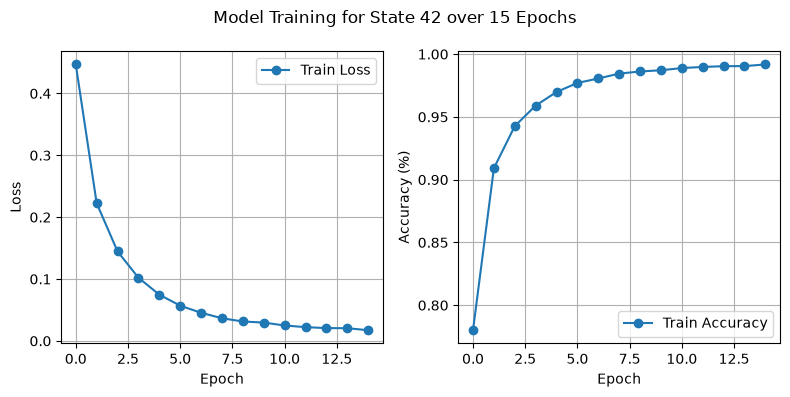

In [16]:
plot_training_performance(train_losses, train_accs, NUM_EPOCHS, RANDOM_STATE)

### Q: Try changing the value of `NUM_EPOCHS`. What happens to the train loss and accuracy plots? What does this tell us about the optimal number of training epochs?

### A: 
More epochs leads to longer curves, and loss goes down as accuracy goes up. This means the optimal number of training epochs is right before it stops improving or starts over memorizing.

### Q: Try changing the value of `RANDOM_STATE`. What happens to the train loss and accuracy plots? What does this tell us about the impact of the initial guess (i.e. epoch 0)?

### A: 
There's a different start at epcoch 0 and slightly different paths. The starting weights matter earlier on but the results usually end up similar

----

## Performance on the Test Set

Here's a helper function to run our model on the test data:

In [17]:

# Evaluate on test set
def run_evaluation_test():
    model.eval()
    test_loss, test_acc, = 0,0

    with torch.no_grad():
        for batch in test_iterator:
            text, text_lengths = batch.text
            labels = batch.label

            text = text.to(device)
            text_lengths = text_lengths.to(device)
            labels = labels.to(device)

            criterion = nn.BCEWithLogitsLoss()
            predictions = model(text, text_lengths).squeeze(1)
            loss = criterion(predictions, labels.float())

            preds = torch.round(torch.sigmoid(predictions))
            acc = (preds == labels).float().mean()

            test_loss += loss.item()
            test_acc += acc.item()

    return print(f"Test Accuracy: {100 * test_acc / len(test_iterator):.2f}%")


Finally, let's check that our model can generalize by processing the test data:

In [ ]:
# Evaluate on test set
run_evaluation_test()

Test Accuracy: 83.82%


----
## Further Exploration 🔎

### Q: What happens to the **test** accuracy as `NUM_EPOCHS` is changed? What does this tell us about our neural network?
Note: remember to re-train your model before running on the test set!

### A:
It goes up at first and then levels or drops. This means there's overfitting, so it's memorizing train data instead of learning general rules

### Q: What happens to the **test** accuracy as `RANDOM_STATE` is changed? What does this tell us about our neural network?
Note: remember to re-train your model before running on the test set!

### A:
It changes a little each run and it shows that randomness affects results so one run isn't enough to judge.

### Q: What happens to your results if you set `find_grained=True`?
Try to predict first and then test your hypothesis by changing the value and re-running the notebook!

### A: 
The accuracy would drop since guessing between more categories is harder.